Saving customer_clustering_dataset.csv to customer_clustering_dataset.csv
Dataset loaded successfully!

First 5 records:
   Annual_Income_k  Spending_Score
0        69.032286       77.424305
1        68.681969       77.142675
2        45.766031       22.425764
3        69.791729       67.987932
4        26.806978       67.690183

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Annual_Income_k  120 non-null    float64
 1   Spending_Score   120 non-null    float64
dtypes: float64(2)
memory usage: 2.0 KB
None

Features used for clustering:
['Annual_Income_k', 'Spending_Score']

Data standardized successfully.

K-Means clustering completed.
EM clustering completed.

Cluster assignments:
    Annual_Income_k  Spending_Score  KMeans_Cluster  EM_Cluster
0         69.032286       77.424305               0           0
1     

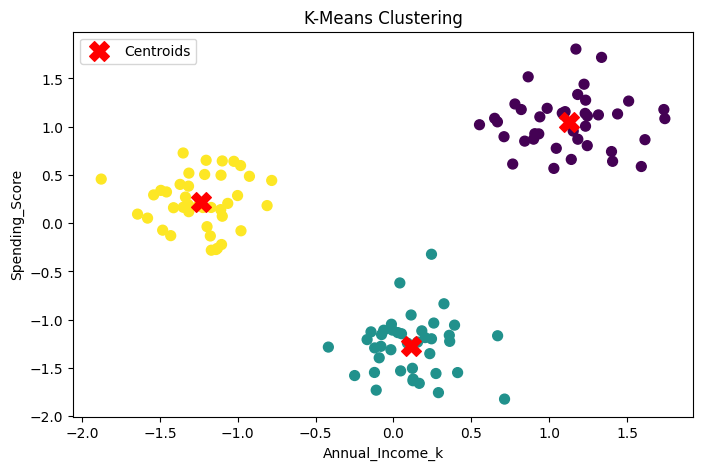

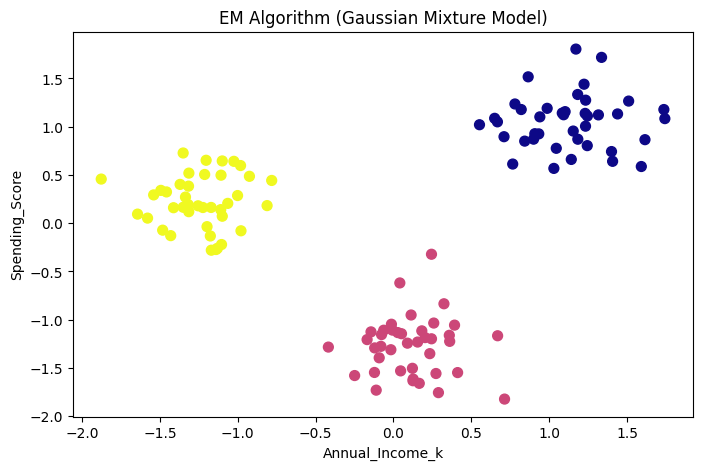


INTERPRETATION

Silhouette Score:
Higher value indicates better-defined and well-separated clusters.

Davies-Bouldin Index:
Lower value indicates better clustering.

Calinski-Harabasz Score:
Higher value generally indicates better-defined clusters.

K-Means assigns each data point to the nearest cluster centroid.
EM using Gaussian Mixture Model estimates the probability that
each data point belongs to each cluster. Therefore, EM can model
clusters with different shapes and distributions.

The clustering quality can be compared using the three evaluation
metrics shown above.



In [1]:
# EXPERIMENT: EM Algorithm and K-Means Clustering

# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Step 2: Upload CSV file
uploaded = files.upload()
filename = list(uploaded.keys())[0]

data = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("\nFirst 5 records:")
print(data.head())
print("\nDataset information:")
print(data.info())

# Step 3: Select numerical features
X = data.select_dtypes(include=np.number)

print("\nFeatures used for clustering:")
print(X.columns.tolist())

# Step 4: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nData standardized successfully.")

# Step 5: Set number of clusters
k = 3

# Step 6: K-Means Clustering
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("\nK-Means clustering completed.")
data["KMeans_Cluster"] = kmeans_labels

# Step 7: EM Algorithm using Gaussian Mixture Model
em = GaussianMixture(
    n_components=k,
    random_state=42
)

em_labels = em.fit_predict(X_scaled)

print("EM clustering completed.")
data["EM_Cluster"] = em_labels

# Step 8: Display cluster assignments
print("\nCluster assignments:")
print(data.head(20))

# Step 9: Evaluate K-Means clustering
kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
kmeans_db = davies_bouldin_score(X_scaled, kmeans_labels)
kmeans_ch = calinski_harabasz_score(X_scaled, kmeans_labels)

# Step 10: Evaluate EM clustering
em_silhouette = silhouette_score(X_scaled, em_labels)
em_db = davies_bouldin_score(X_scaled, em_labels)
em_ch = calinski_harabasz_score(X_scaled, em_labels)

# Step 11: Compare the results
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "EM (Gaussian Mixture)"],
    "Silhouette Score": [kmeans_silhouette, em_silhouette],
    "Davies-Bouldin Index": [kmeans_db, em_db],
    "Calinski-Harabasz Score": [kmeans_ch, em_ch]
})

print("\n==============================================")
print("CLUSTERING PERFORMANCE COMPARISON")
print("==============================================")
print(comparison.to_string(index=False))

# Step 12: Visualize K-Means clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=50
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=200,
    color="red",
    label="Centroids"
)

plt.title("K-Means Clustering")
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.legend()
plt.show()

# Step 13: Visualize EM clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=em_labels,
    cmap="plasma",
    s=50
)

plt.title("EM Algorithm (Gaussian Mixture Model)")
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.show()

# Step 14: Final interpretation
print("\n==============================================")
print("INTERPRETATION")
print("==============================================")

print("""
Silhouette Score:
Higher value indicates better-defined and well-separated clusters.

Davies-Bouldin Index:
Lower value indicates better clustering.

Calinski-Harabasz Score:
Higher value generally indicates better-defined clusters.

K-Means assigns each data point to the nearest cluster centroid.
EM using Gaussian Mixture Model estimates the probability that
each data point belongs to each cluster. Therefore, EM can model
clusters with different shapes and distributions.

The clustering quality can be compared using the three evaluation
metrics shown above.
""")